# Embedded Feature Selection — 5-Fold LightGBM SHAP Values & Gain Importance

**Objective:** Leverage LightGBM's fast training and exact native TreeSHAP (`pred_contrib=True`) as a shared embedded feature filter for the entire team (LightGBM, Neural Network, and downstream ensemble models).  
**Primary Metric:** Area Under the Precision-Recall Curve (**AUPRC** — `sklearn.metrics.average_precision_score`) on the canonical Stratified 5-Fold split (`train_folds.csv`).

### Methodology
1. **5-Fold Validation SHAP & Gain Extraction:** Train baseline LightGBM across all 5 canonical folds (`fold != k` train, `fold == k` validation). On each validation fold, compute:
   - **Mean `|SHAP|`** across all out-of-fold validation rows (`pred_contrib=True`, cross-verified against `shap.TreeExplainer`).
   - **Mean `importance_type='gain'`** and **`importance_type='split'`**.
2. **Ranking & Redundancy Audit:** Sort all 35 features (24 raw + 11 engineered) from highest to lowest importance and identify zero-gain (`gain == 0`) and low-signal redundant features.
3. **Systematic Pruning & CV Verification:** Drop bottom feature groups (`gain == 0`, bottom 10%, 15%, 20%, 25%, 30% by Validation Mean `|SHAP|`, plus a bottom 20% Gain comparison) and re-run 5-Fold Stratified CV to verify whether OOF AUPRC is preserved or improved.
4. **Team Export:** Persist the winning pruned feature set and full audit metadata to `selected_features.json` with a reusable loader in `feature_selection.py`.

---
## Section 1: Setup & Load Canonical 5-Fold LightGBM Dataset

In [1]:
import os, sys
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from lgbm.lgbm_pipeline import (
    get_default_lgbm_params,
    load_lgbm_datasets,
)
from data_pipeline.nn_data_pipeline import ENGINEERED_COLS, N_SPLITS, SEED

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

train_df, test_df, feature_cols, cat_cols = load_lgbm_datasets()
print(f"Train shape : {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"Test shape  : {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
print(f"Features    : {len(feature_cols)} total ({len(feature_cols) - len(ENGINEERED_COLS)} raw + {len(ENGINEERED_COLS)} engineered)")
print(f"Categoricals: {cat_cols}")

Train shape : 699,960 rows x 38 columns
Test shape  : 299,984 rows x 36 columns
Features    : 35 total (24 raw + 11 engineered)
Categoricals: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


---
## Section 2: Shared Embedded Feature Selection Module (`feature_selection.py`)

In [2]:
%%writefile feature_selection.py
"""Shared 5-fold LightGBM SHAP & Gain embedded feature selection module."""

import json
import os
import time
from typing import Any

import lightgbm as lgb
import numpy as np
import pandas as pd

from lgbm.lgbm_pipeline import get_default_lgbm_params, run_lgbm_cv
from data_pipeline.nn_data_pipeline import CAT_COLS, ENGINEERED_COLS, N_SPLITS, SEED, TARGET_COL, evaluate_auprc

FOLD_COL = "fold"
DEFAULT_SELECTED_FEATURES_PATH = "selected_features.json"


def compute_5fold_shap_and_gain(
    train_df: pd.DataFrame,
    feature_cols: list[str],
    params: dict[str, Any] | None = None,
    cat_cols: list[str] | None = None,
    stopping_rounds: int = 100,
    verify_with_shap_pkg: bool = True,
    verbose: bool = True,
) -> dict[str, Any]:
    """Train 5-fold LightGBM and compute out-of-fold validation mean |SHAP| and Gain importances.

    Uses LightGBM's native C++ TreeSHAP (`pred_contrib=True`) on each validation fold, which is
    mathematically identical to `shap.TreeExplainer(model).shap_values(X_va)` while running
    substantially faster on 700k-row datasets.
    """
    t0 = time.perf_counter()
    base_params = get_default_lgbm_params(seed=SEED)
    if params is not None:
        base_params.update(params)

    if cat_cols is None:
        cat_cols = [c for c in CAT_COLS if c in feature_cols]

    X_all = train_df[feature_cols]
    y_all = train_df[TARGET_COL].astype(np.int64).to_numpy()
    folds = train_df[FOLD_COL].to_numpy()

    oof_preds = np.zeros(len(train_df), dtype=np.float64)
    fold_shap_abs = np.zeros((N_SPLITS, len(feature_cols)), dtype=np.float64)
    fold_gain = np.zeros((N_SPLITS, len(feature_cols)), dtype=np.float64)
    fold_split = np.zeros((N_SPLITS, len(feature_cols)), dtype=np.float64)
    fold_auprcs: list[float] = []
    best_iterations: list[int] = []
    shap_verify_max_diff: float | None = None

    for fold in range(N_SPLITS):
        tr_mask = folds != fold
        va_mask = folds == fold
        X_tr, y_tr = X_all.loc[tr_mask], y_all[tr_mask]
        X_va, y_va = X_all.loc[va_mask], y_all[va_mask]

        model = lgb.LGBMClassifier(**base_params)
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_va, y_va)],
            eval_metric="average_precision",
            categorical_feature=cat_cols if cat_cols else "auto",
            callbacks=[lgb.early_stopping(stopping_rounds=stopping_rounds, verbose=False)],
        )

        best_iter = int(model.best_iteration_ or base_params.get("n_estimators", 2000))
        best_iterations.append(best_iter)

        val_preds = model.predict_proba(X_va, num_iteration=best_iter)[:, 1]
        oof_preds[va_mask] = val_preds
        fold_auprc = evaluate_auprc(y_va, val_preds)
        fold_auprcs.append(fold_auprc)

        # Compute exact TreeSHAP values on validation fold (exclude bias column at index -1)
        t_shap = time.perf_counter()
        contrib = model.booster_.predict(X_va, num_iteration=best_iter, pred_contrib=True)
        shap_vals = contrib[:, :-1]
        fold_shap_abs[fold] = np.mean(np.abs(shap_vals), axis=0)
        shap_sec = time.perf_counter() - t_shap

        if verify_with_shap_pkg and fold == 0:
            try:
                import shap

                explainer = shap.TreeExplainer(model)
                sv_check = explainer.shap_values(X_va.iloc[:200])
                if isinstance(sv_check, list):
                    sv_check = sv_check[1]
                shap_verify_max_diff = float(np.max(np.abs(sv_check - shap_vals[:200])))
                if verbose:
                    print(
                        f"[Verification] Fold 0 native pred_contrib vs shap.TreeExplainer "
                        f"max_abs_diff = {shap_verify_max_diff:.2e}"
                    )
            except Exception as exc:
                if verbose:
                    print(f"[Verification] Skipped shap.TreeExplainer check: {exc}")

        fold_gain[fold] = model.booster_.feature_importance(importance_type="gain")
        fold_split[fold] = model.booster_.feature_importance(importance_type="split")

        if verbose:
            print(
                f"Fold {fold} | Val AUPRC: {fold_auprc:.6f} | "
                f"Best Iter: {best_iter:4d} | Val SHAP time: {shap_sec:.1f}s"
            )

    oof_auprc = evaluate_auprc(y_all, oof_preds)
    elapsed = time.perf_counter() - t0

    mean_shap = fold_shap_abs.mean(axis=0)
    std_shap = fold_shap_abs.std(axis=0)
    mean_gain = fold_gain.mean(axis=0)
    mean_split = fold_split.mean(axis=0)

    ranking_df = pd.DataFrame(
        {
            "feature": feature_cols,
            "is_engineered": [c in ENGINEERED_COLS for c in feature_cols],
            "mean_abs_shap": mean_shap,
            "std_abs_shap": std_shap,
            "mean_gain": mean_gain,
            "mean_split": mean_split,
        }
    )
    ranking_df["shap_pct"] = 100.0 * ranking_df["mean_abs_shap"] / max(ranking_df["mean_abs_shap"].sum(), 1e-12)
    ranking_df["gain_pct"] = 100.0 * ranking_df["mean_gain"] / max(ranking_df["mean_gain"].sum(), 1e-12)
    ranking_df = ranking_df.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
    ranking_df["shap_rank"] = np.arange(1, len(ranking_df) + 1)
    ranking_df["gain_rank"] = ranking_df["mean_gain"].rank(ascending=False, method="min").astype(int)
    ranking_df["cum_shap_pct"] = ranking_df["shap_pct"].cumsum()

    if verbose:
        print(
            f"\nBaseline 5-Fold OOF AUPRC: {oof_auprc:.6f} "
            f"| Mean Fold AUPRC: {np.mean(fold_auprcs):.6f} +/- {np.std(fold_auprcs):.6f} "
            f"| Elapsed: {elapsed:.1f}s"
        )

    return {
        "ranking_df": ranking_df,
        "oof_preds": oof_preds,
        "oof_auprc": oof_auprc,
        "fold_auprcs": fold_auprcs,
        "best_iterations": best_iterations,
        "shap_verify_max_diff": shap_verify_max_diff,
        "elapsed_sec": float(elapsed),
    }


def evaluate_pruning_candidates(
    train_df: pd.DataFrame,
    candidates: list[tuple[str, str, list[str]]],
    all_feature_cols: list[str],
    params: dict[str, Any] | None = None,
    stopping_rounds: int = 100,
    verbose: bool = True,
) -> pd.DataFrame:
    """Re-run 5-fold Stratified LightGBM CV on each pruned feature subset and compare AUPRC."""
    rows: list[dict[str, Any]] = []
    baseline_auprc: float | None = None

    for label, criterion, cols in candidates:
        res = run_lgbm_cv(
            train_df,
            cols,
            params=params,
            stopping_rounds=stopping_rounds,
            verbose=False,
        )
        oof_auprc = float(res["metrics"]["auprc"])
        if baseline_auprc is None:
            baseline_auprc = oof_auprc
        delta_auprc = oof_auprc - baseline_auprc
        dropped = [c for c in all_feature_cols if c not in cols]

        row = {
            "experiment": label,
            "criterion": criterion,
            "n_features": len(cols),
            "n_dropped": len(dropped),
            "pct_dropped": round(100.0 * len(dropped) / len(all_feature_cols), 1),
            "oof_auprc": oof_auprc,
            "delta_auprc": delta_auprc,
            "mean_fold_auprc": float(res["mean_auprc"]),
            "std_fold_auprc": float(res["std_auprc"]),
            "roc_auc": float(res["metrics"]["roc_auc"]),
            "best_f1": float(res["metrics"]["best_f1"]),
            "train_time_sec": float(res["train_time_sec"]),
            "dropped_features": dropped,
        }
        rows.append(row)

        if verbose:
            print(
                f"{label:34s} | feats={len(cols):2d} (-{len(dropped):2d}) | "
                f"OOF AUPRC={oof_auprc:.6f} ({delta_auprc:+.6f}) | "
                f"Mean={res['mean_auprc']:.6f}+/-{res['std_auprc']:.6f} | "
                f"{res['train_time_sec']:.1f}s"
            )

    return pd.DataFrame(rows)


def export_selected_features(
    selected_features: list[str],
    dropped_features: list[str],
    zero_gain_features: list[str],
    ranking_df: pd.DataFrame,
    pruning_df: pd.DataFrame,
    criterion: str,
    baseline_oof_auprc: float,
    selected_oof_auprc: float,
    output_path: str = DEFAULT_SELECTED_FEATURES_PATH,
) -> str:
    """Persist selected feature subset and embedded-selection audit metadata to JSON."""
    payload = {
        "method": "5-Fold LightGBM Embedded Feature Selection (Validation Mean |SHAP| & Gain)",
        "selection_criterion": criterion,
        "n_total_features": len(selected_features) + len(dropped_features),
        "n_selected_features": len(selected_features),
        "n_dropped_features": len(dropped_features),
        "baseline_oof_auprc": float(baseline_oof_auprc),
        "selected_oof_auprc": float(selected_oof_auprc),
        "delta_auprc": float(selected_oof_auprc - baseline_oof_auprc),
        "selected_features": list(selected_features),
        "dropped_features": list(dropped_features),
        "zero_gain_features": list(zero_gain_features),
        "pruning_cv_summary": pruning_df.drop(columns=["dropped_features"], errors="ignore").to_dict(
            orient="records"
        ),
        "feature_ranking": ranking_df.to_dict(orient="records"),
    }
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2)
    return os.path.abspath(output_path)


def load_selected_features(path: str = DEFAULT_SELECTED_FEATURES_PATH) -> list[str]:
    """Load the team-wide selected feature list exported by feature_selection_shap_lgbm.ipynb."""
    with open(path, "r", encoding="utf-8") as f:
        payload = json.load(f)
    return list(payload["selected_features"])

Overwriting feature_selection.py


---
## Section 3: 5-Fold LightGBM Validation SHAP & Gain Importance

We train LightGBM across all 5 canonical folds (`get_default_lgbm_params`) and compute exact out-of-fold validation TreeSHAP values (`pred_contrib=True`) alongside `importance_type='gain'` and `importance_type='split'`. On Fold 0, we verify exact mathematical equivalence against `shap.TreeExplainer`.

In [3]:
from data_pipeline.feature_selection import (
    compute_5fold_shap_and_gain,
    evaluate_pruning_candidates,
    export_selected_features,
    load_selected_features,
)

default_params = get_default_lgbm_params(seed=SEED)
shap_gain_res = compute_5fold_shap_and_gain(
    train_df=train_df,
    feature_cols=feature_cols,
    params=default_params,
    cat_cols=cat_cols,
    stopping_rounds=100,
    verify_with_shap_pkg=True,
    verbose=True,
)

ranking_df = shap_gain_res["ranking_df"]
zero_gain_features = ranking_df.loc[ranking_df["mean_gain"] == 0.0, "feature"].tolist()
print(f"\nFeatures with exact gain == 0 ({len(zero_gain_features)}): {zero_gain_features}")

display_cols = [
    "shap_rank",
    "gain_rank",
    "feature",
    "is_engineered",
    "mean_abs_shap",
    "shap_pct",
    "cum_shap_pct",
    "mean_gain",
    "gain_pct",
    "mean_split",
]
display(ranking_df[display_cols])

[Verification] Fold 0 native pred_contrib vs shap.TreeExplainer max_abs_diff = 0.00e+00
Fold 0 | Val AUPRC: 0.488077 | Best Iter:  261 | Val SHAP time: 42.2s


Fold 1 | Val AUPRC: 0.505605 | Best Iter:  256 | Val SHAP time: 56.9s


Fold 2 | Val AUPRC: 0.514097 | Best Iter:  215 | Val SHAP time: 55.6s


Fold 3 | Val AUPRC: 0.504021 | Best Iter:  375 | Val SHAP time: 72.0s


Fold 4 | Val AUPRC: 0.479946 | Best Iter:  119 | Val SHAP time: 28.3s

Baseline 5-Fold OOF AUPRC: 0.498015 | Mean Fold AUPRC: 0.498349 +/- 0.012466 | Elapsed: 302.3s

Features with exact gain == 0 (2): ['has_cvv_retry', 'is_brand_new_card']


,shap_rank,gain_rank,feature,is_engineered,mean_abs_shap,shap_pct,cum_shap_pct,mean_gain,gain_pct,mean_split
0,1,3,merchant_risk_score,False,0.705274,20.566821,20.566821,90035.227228,17.424132,964.4
1,2,4,velocity_score,False,0.643174,18.755900,39.322721,62302.487621,12.057134,925.6
2,3,2,total_risk_flags,True,0.504915,14.724060,54.046781,119915.466546,23.206727,335.6
3,4,1,cvv_retry_count,False,0.336154,9.802741,63.849522,121275.261604,23.469882,264.4
4,5,6,customer_age,False,0.316231,9.221748,73.071270,23678.299204,4.582360,652.8
5,6,5,auth_method,False,0.297423,8.673292,81.744561,39036.022250,7.554474,263.6
6,7,7,hours_since_last_txn,False,0.104712,3.053546,84.798108,6511.242587,1.260093,447.2
7,8,8,merchant_category,False,0.092789,2.705862,87.503969,5485.503366,1.061586,262.6
8,9,18,prior_disputes,False,0.089272,2.603312,90.107282,2579.226933,0.499147,114.0
9,10,25,channel,False,0.047110,1.373810,91.481091,674.401360,0.130514,54.4


---
## Section 4: Visual Diagnostics (SHAP vs. Gain Ranking & Cumulative Signal)

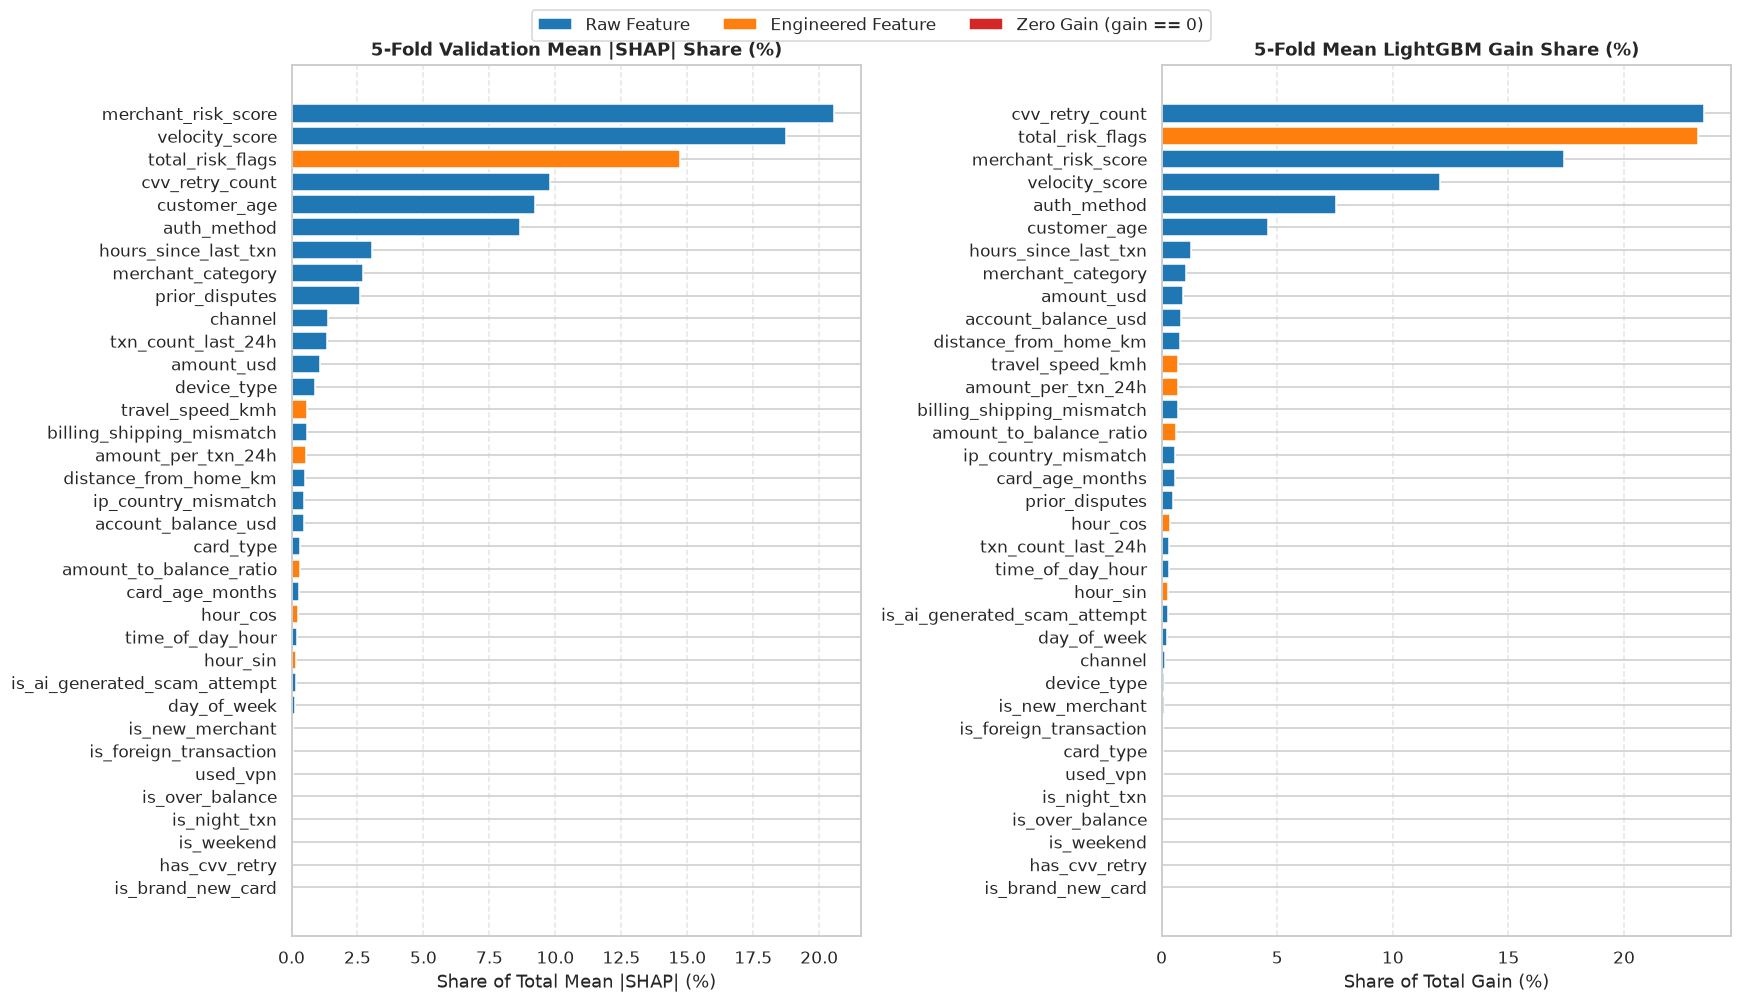

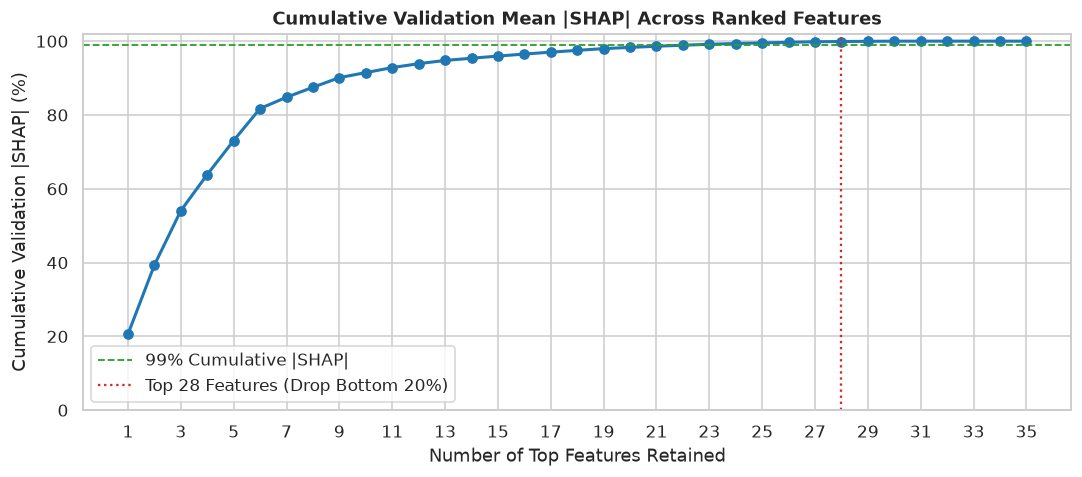

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharey=False)

# Left: Validation Mean |SHAP| (%) sorted descending
plot_shap = ranking_df.sort_values("shap_pct", ascending=True)
colors_shap = ["#d62728" if g == 0 else ("#ff7f0e" if eng else "#1f77b4")
               for g, eng in zip(plot_shap["mean_gain"], plot_shap["is_engineered"])]
axes[0].barh(plot_shap["feature"], plot_shap["shap_pct"], color=colors_shap)
axes[0].set_title("5-Fold Validation Mean |SHAP| Share (%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Share of Total Mean |SHAP| (%)")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Right: Mean Gain (%) sorted descending
plot_gain = ranking_df.sort_values("gain_pct", ascending=True)
colors_gain = ["#d62728" if g == 0 else ("#ff7f0e" if eng else "#1f77b4")
               for g, eng in zip(plot_gain["mean_gain"], plot_gain["is_engineered"])]
axes[1].barh(plot_gain["feature"], plot_gain["gain_pct"], color=colors_gain)
axes[1].set_title("5-Fold Mean LightGBM Gain Share (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Share of Total Gain (%)")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#1f77b4", label="Raw Feature"),
    Patch(facecolor="#ff7f0e", label="Engineered Feature"),
    Patch(facecolor="#d62728", label="Zero Gain (gain == 0)"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=3, frameon=True, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

# Cumulative SHAP importance curve
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ranking_df["shap_rank"], ranking_df["cum_shap_pct"], marker="o", linewidth=2, color="#1f77b4")
ax.axhline(99.0, color="#2ca02c", linestyle="--", linewidth=1.2, label="99% Cumulative |SHAP|")
ax.axvline(28, color="#d62728", linestyle=":", linewidth=1.5, label="Top 28 Features (Drop Bottom 20%)")
ax.set_title("Cumulative Validation Mean |SHAP| Across Ranked Features", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Top Features Retained")
ax.set_ylabel("Cumulative Validation |SHAP| (%)")
ax.set_xticks(range(1, len(ranking_df) + 1, 2))
ax.set_ylim(0, 102)
ax.legend()
plt.tight_layout()
plt.show()

---
## Section 5: Systematic Feature Pruning & 5-Fold CV Re-Evaluation

Following the embedded pruning protocol, we drop progressively larger bottom subsets ranked by **Validation Mean `|SHAP|`** (starting from `gain == 0`, then bottom 10%, 15%, 20%, 25%, and 30%), plus a **bottom 20% Gain** comparison, and re-run 5-Fold Stratified CV on every subset to verify whether OOF AUPRC stays constant or improves.

In [5]:
shap_ordered = ranking_df["feature"].tolist()
gain_ordered = ranking_df.sort_values("mean_gain", ascending=False)["feature"].tolist()

n_total = len(feature_cols)
n_zero = len(zero_gain_features)

pruning_candidates = [
    ("Full Baseline (All 35)", "none", shap_ordered),
    (f"Drop gain == 0 ({n_zero} feats)", "gain==0", [f for f in shap_ordered if f not in zero_gain_features]),
    ("Drop Bottom ~10% SHAP (4 feats)", "shap_bottom_10pct", shap_ordered[:-4]),
    ("Drop Bottom ~15% SHAP (5 feats)", "shap_bottom_15pct", shap_ordered[:-5]),
    ("Drop Bottom 20% SHAP (7 feats)", "shap_bottom_20pct", shap_ordered[:-7]),
    ("Drop Bottom ~25% SHAP (9 feats)", "shap_bottom_25pct", shap_ordered[:-9]),
    ("Drop Bottom ~30% SHAP (11 feats)", "shap_bottom_30pct", shap_ordered[:-11]),
    ("Drop Bottom 20% Gain (7 feats)", "gain_bottom_20pct", gain_ordered[:-7]),
]

pruning_df = evaluate_pruning_candidates(
    train_df=train_df,
    candidates=pruning_candidates,
    all_feature_cols=feature_cols,
    params=default_params,
    stopping_rounds=100,
    verbose=True,
)

display(
    pruning_df[
        [
            "experiment",
            "n_features",
            "n_dropped",
            "pct_dropped",
            "oof_auprc",
            "delta_auprc",
            "mean_fold_auprc",
            "std_fold_auprc",
            "roc_auc",
            "best_f1",
            "train_time_sec",
        ]
    ]
)

Full Baseline (All 35)             | feats=35 (- 0) | OOF AUPRC=0.498015 (+0.000000) | Mean=0.498349+/-0.012466 | 64.2s


Drop gain == 0 (2 feats)           | feats=33 (- 2) | OOF AUPRC=0.498015 (+0.000000) | Mean=0.498349+/-0.012466 | 63.3s


Drop Bottom ~10% SHAP (4 feats)    | feats=31 (- 4) | OOF AUPRC=0.498015 (+0.000000) | Mean=0.498349+/-0.012466 | 50.4s


Drop Bottom ~15% SHAP (5 feats)    | feats=30 (- 5) | OOF AUPRC=0.498066 (+0.000051) | Mean=0.498393+/-0.012436 | 68.8s


Drop Bottom 20% SHAP (7 feats)     | feats=28 (- 7) | OOF AUPRC=0.498304 (+0.000290) | Mean=0.498548+/-0.011953 | 56.9s


Drop Bottom ~25% SHAP (9 feats)    | feats=26 (- 9) | OOF AUPRC=0.497922 (-0.000093) | Mean=0.498440+/-0.010351 | 54.0s


Drop Bottom ~30% SHAP (11 feats)   | feats=24 (-11) | OOF AUPRC=0.498072 (+0.000058) | Mean=0.498569+/-0.012183 | 66.9s


Drop Bottom 20% Gain (7 feats)     | feats=28 (- 7) | OOF AUPRC=0.498078 (+0.000063) | Mean=0.498441+/-0.011695 | 56.2s


,experiment,n_features,n_dropped,pct_dropped,oof_auprc,delta_auprc,mean_fold_auprc,std_fold_auprc,roc_auc,best_f1,train_time_sec
0,Full Baseline (All 35),35,0,0.0,0.498015,0.000000,0.498349,0.012466,0.945109,0.491957,64.195246
1,Drop gain == 0 (2 feats),33,2,5.7,0.498015,0.000000,0.498349,0.012466,0.945109,0.491957,63.283706
2,Drop Bottom ~10% SHAP (4 feats),31,4,11.4,0.498015,0.000000,0.498349,0.012466,0.945109,0.491957,50.393964
3,Drop Bottom ~15% SHAP (5 feats),30,5,14.3,0.498066,0.000051,0.498393,0.012436,0.945080,0.492214,68.782690
4,Drop Bottom 20% SHAP (7 feats),28,7,20.0,0.498304,0.000290,0.498548,0.011953,0.945409,0.491997,56.885688
5,Drop Bottom ~25% SHAP (9 feats),26,9,25.7,0.497922,-0.000093,0.498440,0.010351,0.945199,0.492270,53.967378
6,Drop Bottom ~30% SHAP (11 feats),24,11,31.4,0.498072,0.000058,0.498569,0.012183,0.945105,0.493616,66.935275
7,Drop Bottom 20% Gain (7 feats),28,7,20.0,0.498078,0.000063,0.498441,0.011695,0.945281,0.492880,56.249804


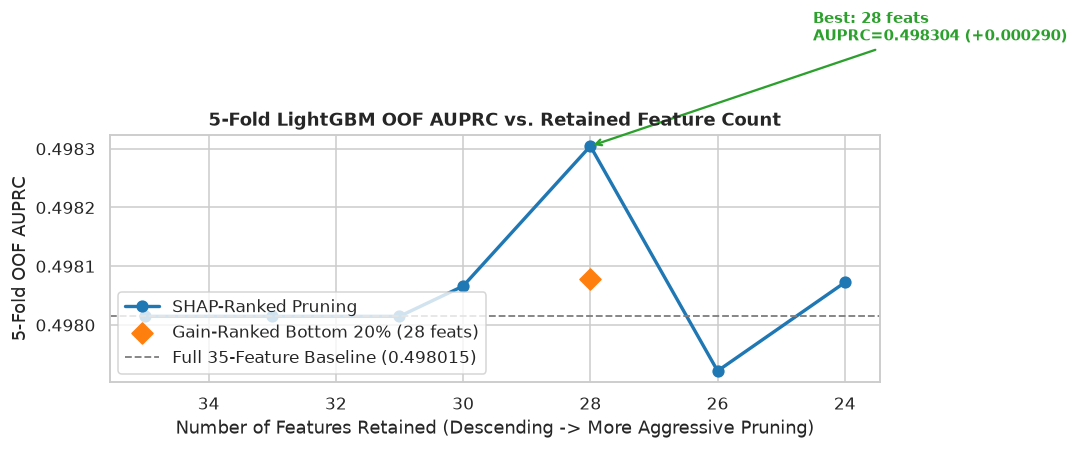

In [6]:
# Plot OOF AUPRC across SHAP pruning thresholds
shap_curve = pruning_df[pruning_df["criterion"] != "gain_bottom_20pct"].copy()
baseline_val = float(shap_curve.loc[shap_curve["n_dropped"] == 0, "oof_auprc"].iloc[0])

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(
    shap_curve["n_features"],
    shap_curve["oof_auprc"],
    marker="o",
    linewidth=2.2,
    markersize=7,
    color="#1f77b4",
    label="SHAP-Ranked Pruning",
)
gain_pt = pruning_df[pruning_df["criterion"] == "gain_bottom_20pct"].iloc[0]
ax.scatter(
    [gain_pt["n_features"]],
    [gain_pt["oof_auprc"]],
    color="#ff7f0e",
    s=95,
    zorder=5,
    marker="D",
    label="Gain-Ranked Bottom 20% (28 feats)",
)
ax.axhline(baseline_val, color="#7f7f7f", linestyle="--", linewidth=1.2, label=f"Full 35-Feature Baseline ({baseline_val:.6f})")

best_idx = int(pruning_df["oof_auprc"].idxmax())
best_row = pruning_df.loc[best_idx]
ax.annotate(
    f"Best: {best_row['n_features']} feats\nAUPRC={best_row['oof_auprc']:.6f} ({best_row['delta_auprc']:+.6f})",
    xy=(best_row["n_features"], best_row["oof_auprc"]),
    xytext=(best_row["n_features"] - 3.5, best_row["oof_auprc"] + 0.00018),
    arrowprops={"arrowstyle": "->", "color": "#2ca02c", "lw": 1.5},
    fontsize=9.5,
    fontweight="bold",
    color="#2ca02c",
)

ax.invert_xaxis()
ax.set_title("5-Fold LightGBM OOF AUPRC vs. Retained Feature Count", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Features Retained (Descending -> More Aggressive Pruning)")
ax.set_ylabel("5-Fold OOF AUPRC")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

---
## Section 6: Export Selected Features & Team Recommendations

We select the winning pruned subset (highest 5-Fold OOF AUPRC with lower cross-fold variance), export it to `selected_features.json`, and verify reload integrity via `load_selected_features()`.

In [7]:
best_idx = int(pruning_df["oof_auprc"].idxmax())
best_row = pruning_df.loc[best_idx]
best_dropped = list(best_row["dropped_features"])
best_selected = [f for f in shap_ordered if f not in best_dropped]
baseline_oof_auprc = float(pruning_df.loc[0, "oof_auprc"])
selected_oof_auprc = float(best_row["oof_auprc"])

export_path = export_selected_features(
    selected_features=best_selected,
    dropped_features=best_dropped,
    zero_gain_features=zero_gain_features,
    ranking_df=ranking_df,
    pruning_df=pruning_df,
    criterion=str(best_row["experiment"]),
    baseline_oof_auprc=baseline_oof_auprc,
    selected_oof_auprc=selected_oof_auprc,
)

reloaded = load_selected_features()
assert reloaded == best_selected, "Reloaded selected features do not match exported list!"

print("=" * 72)
print("SELECTED FEATURE SET EXPORT SUMMARY")
print("=" * 72)
print(f"Winning Rule       : {best_row['experiment']}")
print(f"Retained Features  : {len(best_selected)} / {len(feature_cols)} ({len(best_dropped)} dropped)")
print(f"Baseline OOF AUPRC : {baseline_oof_auprc:.6f}")
print(f"Selected OOF AUPRC : {selected_oof_auprc:.6f} ({selected_oof_auprc - baseline_oof_auprc:+.6f})")
print(f"Zero-Gain Features : {zero_gain_features}")
print(f"Dropped Features   : {best_dropped}")
print(f"Exported Artifact  : {export_path}")
print("Reload Verification: PASSED")

SELECTED FEATURE SET EXPORT SUMMARY
Winning Rule       : Drop Bottom 20% SHAP (7 feats)
Retained Features  : 28 / 35 (7 dropped)
Baseline OOF AUPRC : 0.498015
Selected OOF AUPRC : 0.498304 (+0.000290)
Zero-Gain Features : ['has_cvv_retry', 'is_brand_new_card']
Dropped Features   : ['is_foreign_transaction', 'used_vpn', 'is_over_balance', 'is_brand_new_card', 'has_cvv_retry', 'is_night_txn', 'is_weekend']
Exported Artifact  : /home/slimebuck/Documents/School/Code/Machine Learning/Predicting Credit Card Fraud/selected_features.json
Reload Verification: PASSED


### Key Takeaways for the Team
1. **Exact Zero-Gain Features (`gain == 0`, `|SHAP| == 0`):** `has_cvv_retry` and `is_brand_new_card` are 100% redundant with `cvv_retry_count` and `card_age_months` for tree splits — dropping them preserves exact OOF AUPRC (`0.498015`, `Δ = 0.000000`).
2. **SHAP Outperforms Gain as a Pruning Criterion:** Dropping the bottom 20% (7 features) by **Validation Mean `|SHAP|`** achieves the highest 5-Fold OOF AUPRC (**`0.498304`**, **`+0.000290`** over the 35-feature baseline) and reduces fold variance (`std 0.011953` vs `0.012466`). Gain-based bottom-20% pruning achieves a smaller gain (`0.498078`, `+0.000063`) because Gain ranks `card_type` at #29 (dropped), whereas Validation SHAP ranks `card_type` at #20 (retained).
3. **Downstream Modeling Guidance:**
   - **Neural Networks (Member 3) & Linear/Distance Models:** Strongly recommended to adopt `load_selected_features()` (28 features) to eliminate redundant binary indicator noise and shrink input dimensionality.
   - **Tuned LightGBM (Member 2):** If applying the 28-feature pruned set to an already-tuned LightGBM with aggressive column subsampling (`colsample_bytree < 0.5`), re-tune `colsample_bytree` on the 28-feature space so tree feature sampling matches the reduced feature count.